In [34]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
cmap = { 0:'r',1:'g',2:'b',3:'g',4:'k' }

In [35]:
def ondas(t, R, L, Ep, w, I0, RTC, Z2, phi):
    denominador         = R**2 + (w*L)**2
    regime_permentente  = (Ep * R * np.sin(w*t+phi) - w*L*np.cos(w*t+phi)) / denominador
    transitorio         = (Ep*(w*L*np.cos(phi)  - R*np.sin(phi) )/ denominador + I0) * np.exp(-R*t/L)
    total               = regime_permentente + transitorio
    return [regime_permentente,  transitorio, total, t]

(-30.0, 30.0)

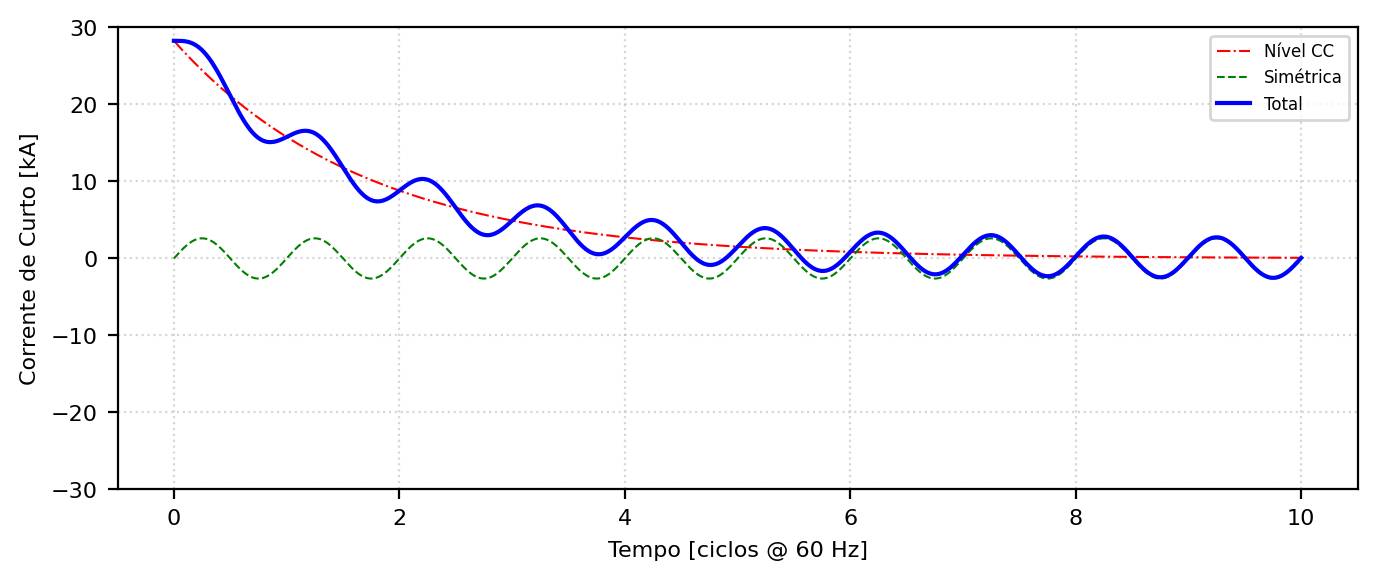

In [60]:
phi = np.array([0, 2*np.pi/3, -2*np.pi/3])
w=2*np.pi*60
rp, tr, total, tempo = ondas(t=np.arange(0, 10/60, 10e-6), R=91.995e-3, L=2.63e-3, Ep=34.5e3*np.sqrt(2/3), w=2*np.pi*60, I0=70*np.sqrt(2), RTC=300/5, Z2=0.334, phi=0)
fig, ax = plt.subplots(figsize=(8,3), dpi=200);
ax.plot(w*tempo/(2*np.pi), tr/1000, label='Nível CC', color='r', ls='-.', lw=0.75)
ax.plot(w*tempo/(2*np.pi), rp/1000, label='Simétrica', color='g', ls="--", lw=0.75)
ax.plot(w*tempo/(2*np.pi), total/1000, label='Total', color='b')
ax.legend(fontsize=6)
ax.grid(ls=":", alpha=0.5)
ax.set_xlabel('Tempo [ciclos @ 60 Hz]')
ax.set_ylabel('Corrente de Curto [kA]')
ax.set_ylim(-30,30)

(-30.0, 30.0)

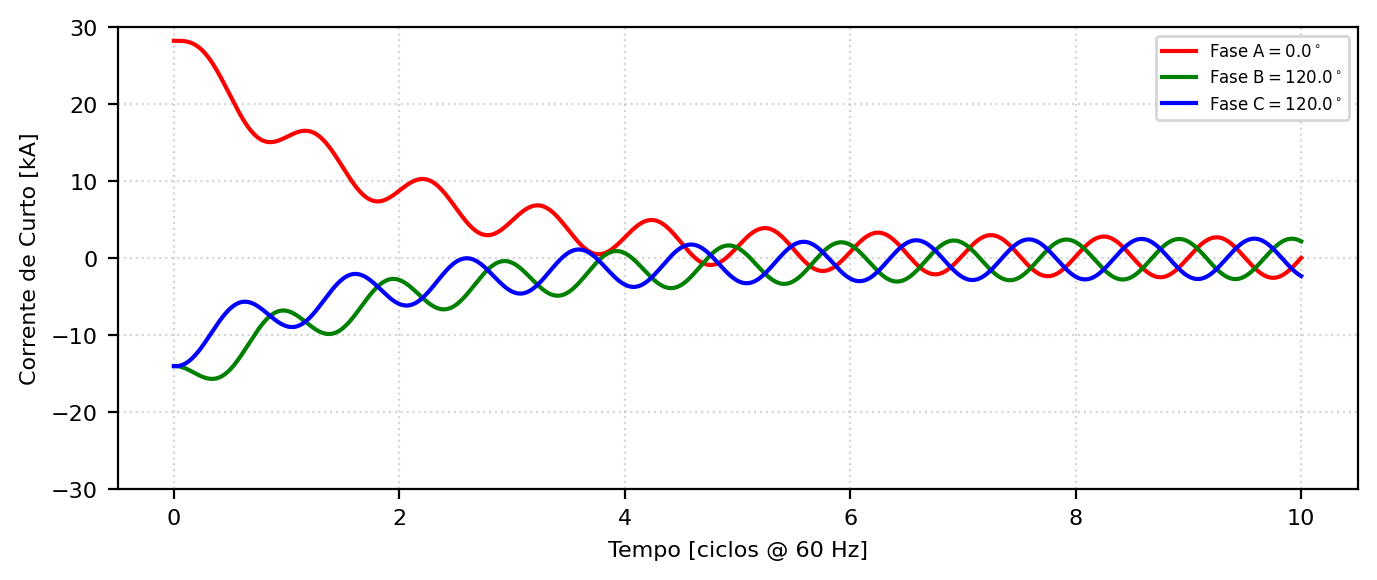

In [45]:
phi = np.array([0, 2*np.pi/3, -2*np.pi/3])
w=2*np.pi*60
fig, ax = plt.subplots(figsize=(8,3), dpi=200);
for fase in phi:
    rp, tr, total, tempo = ondas(t=np.arange(0, 10/60, 10e-6), R=91.995e-3, L=2.63e-3, Ep=34.5e3*np.sqrt(2/3), w=2*np.pi*60, I0=70*np.sqrt(2), RTC=300/5, Z2=0.334, phi=fase)
    plt.rcParams['font.size'] = 8
    if fase==phi[0]:
        linha_ = 'r'
        fase_ = 'Fase A$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    elif fase==phi[1]:
        linha_ = 'g'
        fase_ = 'Fase B$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    else:
        linha_ = 'b'
    ax.plot(w*tempo/(2*np.pi), total/1000, label=fase_, color=linha_)
    fase_ = 'Fase C$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    ax.legend(fontsize=6)
ax.grid(ls=":", alpha=0.5)
ax.set_xlabel('Tempo [ciclos @ 60 Hz]')
ax.set_ylabel('Corrente de Curto [kA]')
ax.set_ylim(-30,30)

(-500.0, 500.0)

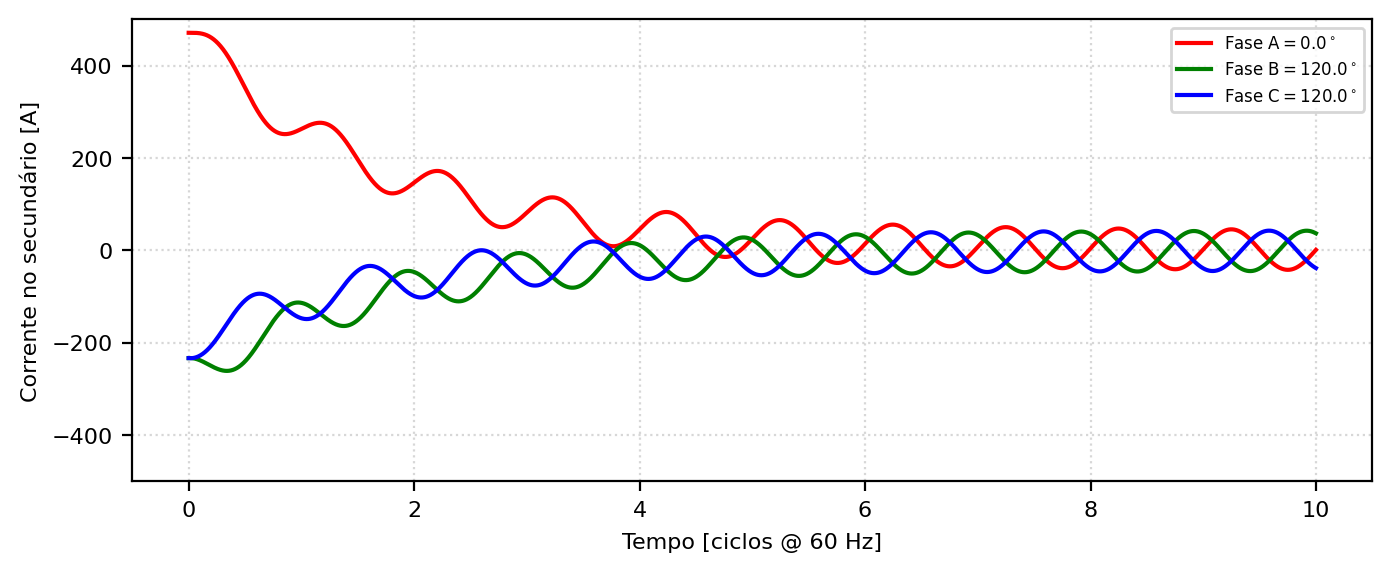

In [62]:
phi = np.array([0, 2*np.pi/3, -2*np.pi/3])
w=2*np.pi*60
RTC = 300/5
fig, ax = plt.subplots(figsize=(8,3), dpi=200);
for fase in phi:
    rp, tr, total, tempo = ondas(t=np.arange(0, 10/60, 10e-6), R=91.995e-3, L=2.63e-3, Ep=34.5e3*np.sqrt(2/3), w=2*np.pi*60, I0=70*np.sqrt(2), RTC=300/5, Z2=0.334, phi=fase)
    plt.rcParams['font.size'] = 8
    if fase==phi[0]:
        linha_ = 'r'
        fase_ = 'Fase A$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    elif fase==phi[1]:
        linha_ = 'g'
        fase_ = 'Fase B$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    else:
        linha_ = 'b'
    ax.plot(w*tempo/(2*np.pi), total/RTC, label=fase_, color=linha_)
    fase_ = 'Fase C$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    ax.legend(fontsize=6)
ax.grid(ls=":", alpha=0.5)
ax.set_xlabel('Tempo [ciclos @ 60 Hz]')
ax.set_ylabel('Corrente no secundário [A]')
ax.set_ylim(-500,500)

(-200.0, 200.0)

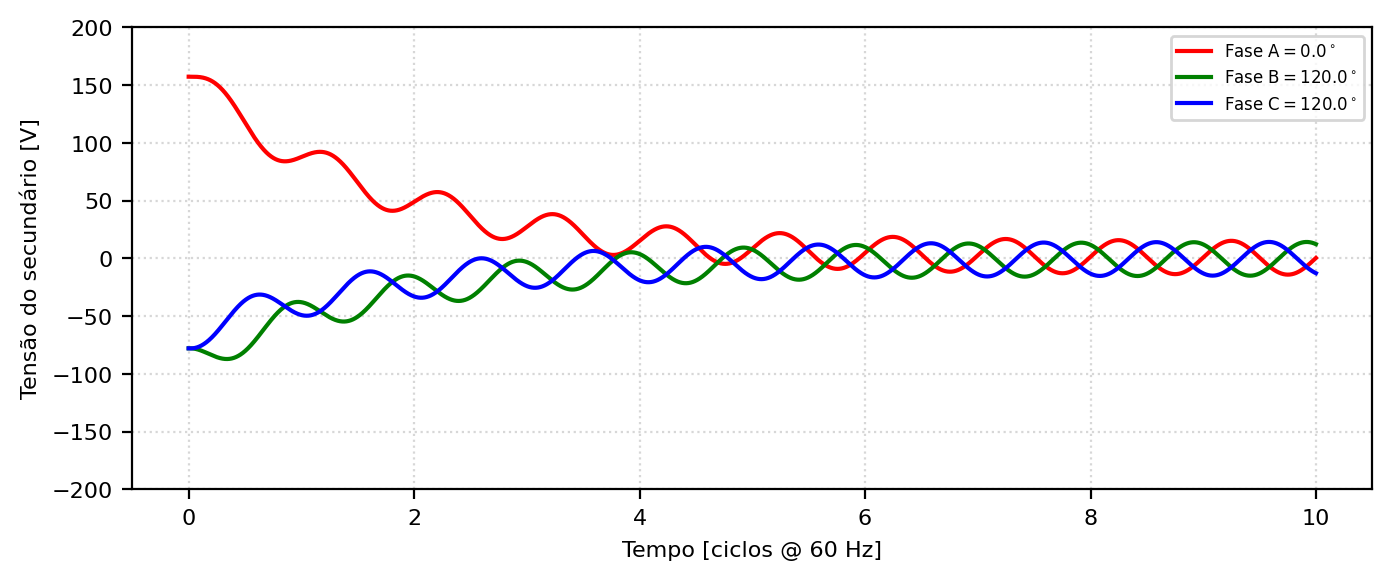

In [71]:
phi = np.array([0, 2*np.pi/3, -2*np.pi/3])
w=2*np.pi*60
RTC = 300/5
Z2=0.334
fig, ax = plt.subplots(figsize=(8,3), dpi=200);
for fase in phi:
    rp, tr, total, tempo = ondas(t=np.arange(0, 10/60, 10e-6), R=91.995e-3, L=2.63e-3, Ep=34.5e3*np.sqrt(2/3), w=2*np.pi*60, I0=70*np.sqrt(2), RTC=300/5, Z2=0.334, phi=fase)
    plt.rcParams['font.size'] = 8
    if fase==phi[0]:
        linha_ = 'r'
        fase_ = 'Fase A$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    elif fase==phi[1]:
        linha_ = 'g'
        fase_ = 'Fase B$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    else:
        linha_ = 'b'
    ax.plot(w*tempo/(2*np.pi), Z2*total/RTC, label=fase_, color=linha_)
    fase_ = 'Fase C$=$'+str(np.round(fase*180/np.pi, 0))+'$^\\circ$'
    ax.legend(fontsize=6)
ax.grid(ls=":", alpha=0.5)
ax.set_xlabel('Tempo [ciclos @ 60 Hz]')
ax.set_ylabel('Tensão do secundário [V]')
ax.set_ylim(-200,200)

In [ ]:
def corrente2(t=np.arange(0, 10/60, 10e-6), R=91.995e-3, L=2.63e-3, Ep=34.5e3*np.sqrt(2/3), w=2*np.pi*60, I0=70*np.sqrt(2), RTC=300/5, Z2=0.334, phi=0):
    plt.rcParams['font.size'] = 8
    plt.rcParams['font.family'] = 'serif'
    tau = L/R
    denominador         = R**2 + (w*L)**2
    regime_permentente  = (Ep * R * np.sin(w*t+phi) - w*L*np.cos(w*t+phi)) / denominador
    transitorio         = ((Ep*( w*L*np.cos(phi)  - R*np.sin(phi) )/ denominador) + I0) * np.exp(-R*t/L)
    total               = regime_permentente + transitorio
    fig, ax = plt.subplots(figsize=(8,2), dpi=200);
    # ax.plot(t*w/(2*np.pi), regime_permentente/RTC, label="regime", lw=1, ls="--")
    # ax.plot(t*w/(2*np.pi), transitorio, label="transitorio", lw=1, ls="--")
    ax.plot(t*w/(2*np.pi), total/RTC, color='green')
    ax.legend(fontsize=6)
    ax.grid(":")
    ax.set_xlabel('Tempo [ciclos @ 60 Hz]')
    ax.set_ylabel('Corrente no secundário do TC [A]')
    return [total, transitorio, regime_permentente, fig, tau]

In [ ]:
def tensao2(t=np.arange(0, 10/60, 10e-6), R=91.995e-3, L=2.63e-3, Ep=34.5e3*np.sqrt(2/3), w=2*np.pi*60, I0=70*np.sqrt(2), RTC=300/5, Z2=0.334, phi=0):
    plt.rcParams['font.size'] = 8
    plt.rcParams['font.family'] = 'serif'
    tau = L/R
    denominador         = R**2 + (w*L)**2
    regime_permentente  = (Ep * R * np.sin(w*t+phi) - w*L*np.cos(w*t+phi)) / denominador
    transitorio         = (Ep*(w*L*np.cos(phi)  - R*np.sin(phi) )/ denominador + I0) * np.exp(-R*t/L)
    total               = regime_permentente + transitorio
    fig, ax = plt.subplots(figsize=(8,2), dpi=200);
    # ax.plot(t*w/(2*np.pi), regime_permentente/RTC, label="regime", lw=1, ls="--")
    # ax.plot(t*w/(2*np.pi), transitorio, label="transitorio", lw=1, ls="--")
    ax.plot(t*w/(2*np.pi), Z2*total/RTC, color='green')
    ax.legend(fontsize=6)
    ax.grid(":")
    ax.set_xlabel('Tempo [ciclos @ 60 Hz]')
    ax.set_ylabel('Tensão no secudário do TC [V]')
    ax.set_ylim(-300, 300)
    return [total, transitorio, regime_permentente, fig, tau]

In [ ]:
i, it, ir, fig, tau = corrente(t=np.arange(0, 10/60, 10e-6), R=91.995e-3, L=2.63e-3, Ep=34.5e3*np.sqrt(2/3), w=2*np.pi*60, I0=70*np.sqrt(2), RTC=300/5, Z2=0.334, phi=0)
fig.show()

In [ ]:
maximo = np.max(i)

maximo, 2*it[0]

In [ ]:
maximo/1.41

In [ ]:
# Define V and I in terms of s, the Laplace variable
V_s_sin = sp.laplace_transform(Ep*sp.sin(w*t), t, s)[0]
V_s_cos = sp.laplace_transform(Ep*sp.cos(w*t), t, s)[0]
V_s = sp.laplace_transform(Ep*sp.sin(w*t+phi), t, s)[0]

In [ ]:
I_s_sen = (V_s_sin + L*I0) / (R+s*L)
I_s_cos = (V_s_cos + L*I0) / (R+s*L)

In [ ]:
# Now compute the inverse Laplace transform
I_t_sen = sp.inverse_laplace_transform(I_s_sen, s, t)
I_t_cos = sp.inverse_laplace_transform(I_s_cos, s, t)

In [ ]:
I_t_sen

In [ ]:
sp.latex(I_t_sen)

In [ ]:
f_sen = sp.lambdify((t, R, L, Ep, w, I0), I_t_sen, "numpy")
f_cos = sp.lambdify((t, R, L, Ep, w, I0), I_t_cos, "numpy")

In [ ]:
tt_p = np.arange(0, 0.2, 10e-6);
tt_n = np.arange(-4/60, 10e-6, 10e-6);
fig, ax = plt.subplots()
ax.plot(tt_p, f_sen(tt_p, 0.13, 3.72e-3, 34.5e3*np.sqrt(2/3), 2*np.pi*60, 70), label='total')
ax.plot(tt_n, 70*np.cos(2*np.pi*60*tt_n))
# ax.plot(tt, f_cos(tt, 0.13, 3.72e-3, 34.5e3*np.sqrt(2/3), 2*np.pi*60, 70))

In [ ]:
f_sen(0, 0.13, 3.72e-3, 34.5e3*np.sqrt(2/3), 2*np.pi*60, 70)